In [1]:
!nvidia-smi

Tue Sep 22 10:05:27 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   48C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
!git clone https://github.com/meryemsakin/helmet-detection-yolov8.git

Cloning into 'helmet-detection-yolov8'...
remote: Enumerating objects: 93, done.
remote: Counting objects: 100% (50/50), done.
remote: Compressing objects: 100% (49/49), done.
remote: Total 93 (delta 27), reused 5 (delta 1), pack-reused 43 (from 1)
Receiving objects: 100% (93/93), 60.35 MiB | 19.96 MiB/s, done.
Resolving deltas: 100% (32/32), done.


In [3]:
!ls -la

total 20
drwxr-xr-x 1 root root 4096 Sep 22 10:06 .
drwxr-xr-x 1 root root 4096 Sep 22 10:03 ..
drwxr-xr-x 4 root root 4096 Sep  4 13:32 .config
drwxr-xr-x 7 root root 4096 Sep 22 10:06 helmet-detection-yolov8
drwxr-xr-x 1 root root 4096 Sep  4 13:32 sample_data


In [4]:
!pip install -q ultralytics opencv-python supervision pandas matplotlib seaborn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 2.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.2/88.2 kB 9.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 40.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 385.0/385.0 kB 35.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.8/35.8 MB 61.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 144.3/144.3 kB 14.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.7/88.7 kB 8.4 MB/s eta 0:00:00


In [5]:
import ultralytics
import cv2
import supervision as sv
import pandas as pd

print("Ultralytics:", ultralytics.__version__)
print("OpenCV:", cv2.__version__)
print("Supervision:", sv.__version__)
print("All libraries loaded successfully!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics: 8.4.158
OpenCV: 5.0.0
Supervision: 0.30.4
All libraries loaded successfully!


In [6]:
%cd /content/helmet-detection-yolov8

/content/helmet-detection-yolov8


In [7]:
!find models -type f

models/hemletYoloV8_100epochs.pt
models/helmetV5_1.pt
models/hemletYoloV8_25epochs.pt


In [8]:
!find test_images -type f

test_images/hard_hat_workers42.png
test_images/hard_hat_workers55.png
test_images/hard_hat_workers43.png
test_images/image_4.jpg
test_images/image_6.jpg
test_images/image_5.jpg
test_images/hard_hat_workers44.png
test_images/hard_hat_workers54.png
test_images/image_7.jpg
test_images/hard_hat_workers56.png
test_images/image_1.jpg


In [9]:
!sed -n '1,300p' main.py

import cv2
import supervision as sv
import os
from datetime import datetime
import sys

from utils.helperFunctions import *
from ultralytics import YOLO


# source = "../RESOURCES\helmet.mp4"
# Custom trained Model we are using for helmet detection
model = YOLO("/Users/meryem/Downloads/Safety-Helmet-Detection-yoloV8-main/models/hemletYoloV8_100epochs.pt")

# frame width and height
frame_wid = 640
frame_hyt = 480


def processImages(image_path_list, image_name_list, image_storage_folder):
    """
    Process images in the given list, detect helmets using a pre-trained YOLOv5 model,
    and store the annotated images and detection results in the output folder.

    Args:
        - image_path_list: A list of image paths to be processed.
        - image_name_list: A list of image names corresponding to the images in image_path_list.
        - image_storage_folder: The path to the output folder where annotated images and detection results are to be stored.

    Returns:
        - csv_result

In [10]:
from ultralytics import YOLO

model_path = "/content/helmet-detection-yolov8/models/helmetYoloV8_100epochs.pt"

model = YOLO(model_path)

print("Model loaded successfully!")
print("Model classes:")
print(model.names)

FileNotFoundError: [Errno 2] No such file or directory: '/content/helmet-detection-yolov8/models/helmetYoloV8_100epochs.pt'

In [11]:
import os

print("Current directory:")
print(os.getcwd())

print("\nRepository contents:")
!ls -la /content/helmet-detection-yolov8

print("\nModels folder:")
!ls -la /content/helmet-detection-yolov8/models

Current directory:
/content/helmet-detection-yolov8

Repository contents:
total 3276
drwxr-xr-x 7 root root    4096 Sep 22 10:06 .
drwxr-xr-x 1 root root    4096 Sep 22 10:06 ..
-rw-r--r-- 1 root root  685114 Sep 22 10:06 allresults.jpeg
-rw-r--r-- 1 root root  113258 Sep 22 10:06 cmatrix.png
drwxr-xr-x 8 root root    4096 Sep 22 10:06 .git
-rw-r--r-- 1 root root  231463 Sep 22 10:06 graph.png
-rw-r--r-- 1 root root 2275135 Sep 22 10:06 helmet-detection-yolov8.ipynb
-rw-r--r-- 1 root root    4274 Sep 22 10:06 main.py
drwxr-xr-x 2 root root    4096 Sep 22 10:06 models
-rw-r--r-- 1 root root    3828 Sep 22 10:06 README.md
drwxr-xr-x 3 root root    4096 Sep 22 10:06 Result
drwxr-xr-x 2 root root    4096 Sep 22 10:06 test_images
drwxr-xr-x 3 root root    4096 Sep 22 10:06 utils

Models folder:
total 58008
drwxr-xr-x 2 root root     4096 Sep 22 10:06 .
drwxr-xr-x 7 root root     4096 Sep 22 10:06 ..
-rw-r--r-- 1 root root 14318717 Sep 22 10:06 helmetV5_1.pt
-rw-r--r-- 1 root root 22539320 S

In [12]:
from ultralytics import YOLO

model_path = "/content/helmet-detection-yolov8/models/helmetYoloV8_100epochs.pt"

model = YOLO(model_path)

print("Model loaded successfully!")
print("Model classes:")
print(model.names)

FileNotFoundError: [Errno 2] No such file or directory: '/content/helmet-detection-yolov8/models/helmetYoloV8_100epochs.pt'

In [13]:
import os

model_dir = "/content/helmet-detection-yolov8/models"

print("Models directory exists:", os.path.exists(model_dir))
print("\nExact files:")
for f in os.listdir(model_dir):
    print(repr(f))

print("\nChecking exact model path:")
model_path = os.path.join(model_dir, "helmetYoloV8_100epochs.pt")
print(model_path)
print("Exists:", os.path.exists(model_path))

Models directory exists: True

Exact files:
'hemletYoloV8_100epochs.pt'
'helmetV5_1.pt'
'hemletYoloV8_25epochs.pt'

Checking exact model path:
/content/helmet-detection-yolov8/models/helmetYoloV8_100epochs.pt
Exists: False


In [14]:
!find /content/helmet-detection-yolov8/models -maxdepth 1 -type f -print

/content/helmet-detection-yolov8/models/hemletYoloV8_100epochs.pt
/content/helmet-detection-yolov8/models/helmetV5_1.pt
/content/helmet-detection-yolov8/models/hemletYoloV8_25epochs.pt


In [15]:
import glob

model_files = glob.glob("/content/helmet-detection-yolov8/models/*.pt")

print("Found model files:")
for f in model_files:
    print(repr(f))

Found model files:
'/content/helmet-detection-yolov8/models/hemletYoloV8_100epochs.pt'
'/content/helmet-detection-yolov8/models/helmetV5_1.pt'
'/content/helmet-detection-yolov8/models/hemletYoloV8_25epochs.pt'


In [16]:
from ultralytics import YOLO

model_path = [f for f in model_files if "100epochs" in f][0]

print("Using model:")
print(model_path)

model = YOLO(model_path)

print("\nModel loaded successfully!")
print("Model classes:")
print(model.names)

Using model:
/content/helmet-detection-yolov8/models/hemletYoloV8_100epochs.pt

Model loaded successfully!
Model classes:
{0: 'head', 1: 'helmet', 2: 'person'}



image 1/1 /content/helmet-detection-yolov8/test_images/image_1.jpg: 544x800 3 helmets, 17.5ms
Speed: 178.9ms preprocess, 17.5ms inference, 40.3ms postprocess per image at shape (1, 3, 544, 800)


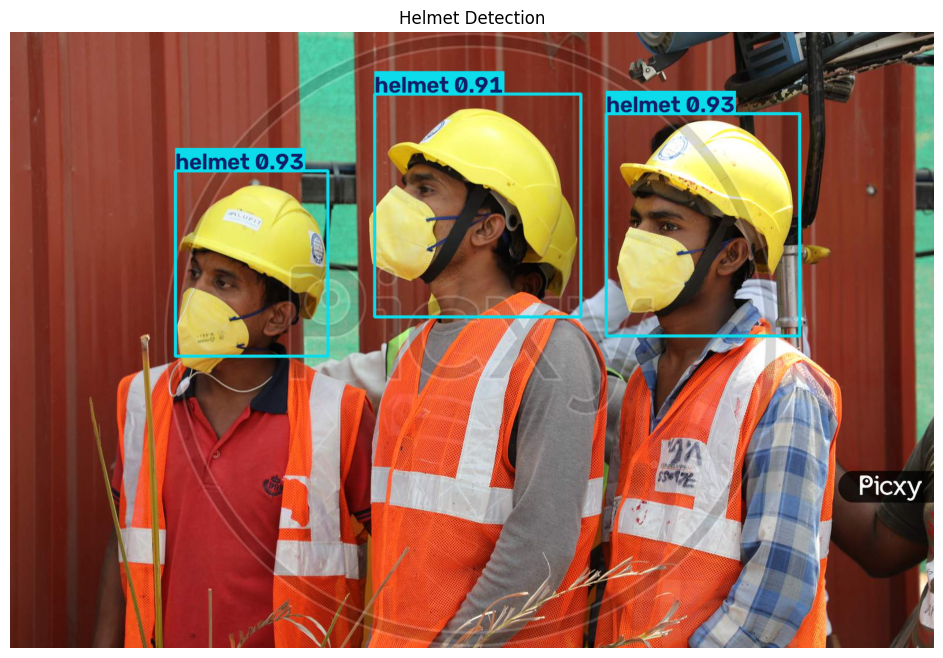

In [17]:
import cv2
import matplotlib.pyplot as plt

image_path = "/content/helmet-detection-yolov8/test_images/image_1.jpg"

results = model(image_path)

annotated_image = results[0].plot()

plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Helmet Detection")
plt.show()

In [18]:
import os
import cv2
import matplotlib.pyplot as plt

input_folder = "/content/helmet-detection-yolov8/test_images"
output_folder = "/content/helmet-detection-yolov8/colab_results"

os.makedirs(output_folder, exist_ok=True)

image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

for filename in os.listdir(input_folder):

    if not filename.lower().endswith(image_extensions):
        continue

    image_path = os.path.join(input_folder, filename)

    results = model(image_path, verbose=False)

    annotated = results[0].plot()

    output_path = os.path.join(output_folder, filename)
    cv2.imwrite(output_path, annotated)

print("All images processed successfully!")
print("Results saved in:")
print(output_folder)

All images processed successfully!
Results saved in:
/content/helmet-detection-yolov8/colab_results


In [19]:
!ls -lh /content/helmet-detection-yolov8/colab_results

total 3.5M
-rw-r--r-- 1 root root 339K Sep 22 10:14 hard_hat_workers42.png
-rw-r--r-- 1 root root 255K Sep 22 10:14 hard_hat_workers43.png
-rw-r--r-- 1 root root 265K Sep 22 10:14 hard_hat_workers44.png
-rw-r--r-- 1 root root 293K Sep 22 10:14 hard_hat_workers54.png
-rw-r--r-- 1 root root 248K Sep 22 10:14 hard_hat_workers55.png
-rw-r--r-- 1 root root 346K Sep 22 10:14 hard_hat_workers56.png
-rw-r--r-- 1 root root 407K Sep 22 10:14 image_1.jpg
-rw-r--r-- 1 root root 145K Sep 22 10:14 image_4.jpg
-rw-r--r-- 1 root root 188K Sep 22 10:14 image_5.jpg
-rw-r--r-- 1 root root 797K Sep 22 10:14 image_6.jpg
-rw-r--r-- 1 root root 195K Sep 22 10:14 image_7.jpg


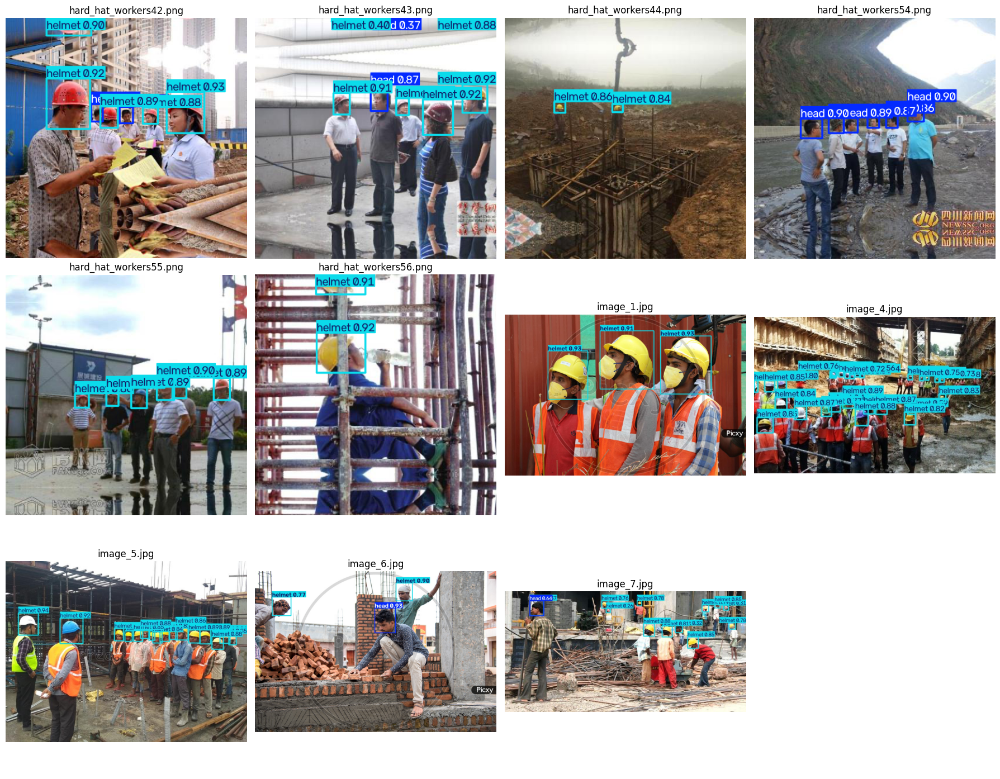

In [20]:
import os
import cv2
import matplotlib.pyplot as plt

result_files = sorted(os.listdir(output_folder))

# Keep only image files
result_files = [
    f for f in result_files
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
]

fig, axes = plt.subplots(3, 4, figsize=(18, 14))
axes = axes.flatten()

for i, filename in enumerate(result_files):
    image_path = os.path.join(output_folder, filename)
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    axes[i].imshow(image)
    axes[i].set_title(filename)
    axes[i].axis("off")

# Hide unused subplot
for i in range(len(result_files), len(axes)):
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [21]:
import os
import pandas as pd

input_folder = "/content/helmet-detection-yolov8/test_images"

rows = []

image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

for filename in sorted(os.listdir(input_folder)):

    if not filename.lower().endswith(image_extensions):
        continue

    image_path = os.path.join(input_folder, filename)

    results = model(image_path, verbose=False)[0]

    class_counts = {
        "head": 0,
        "helmet": 0,
        "person": 0
    }

    confidences = {
        "head": [],
        "helmet": [],
        "person": []
    }

    for cls, conf in zip(
        results.boxes.cls.cpu().numpy(),
        results.boxes.conf.cpu().numpy()
    ):
        class_name = model.names[int(cls)]

        if class_name in class_counts:
            class_counts[class_name] += 1
            confidences[class_name].append(float(conf))

    rows.append({
        "Image": filename,
        "Head Count": class_counts["head"],
        "Helmet Count": class_counts["helmet"],
        "Person Count": class_counts["person"],
        "Helmet Confidence": round(
            max(confidences["helmet"], default=0), 2
        ),
        "Head Confidence": round(
            max(confidences["head"], default=0), 2
        )
    })

df = pd.DataFrame(rows)

df

,Image,Head Count,Helmet Count,Person Count,Helmet Confidence,Head Confidence
0,hard_hat_workers42.png,2,5,0,0.93,0.88
1,hard_hat_workers43.png,2,6,0,0.92,0.87
2,hard_hat_workers44.png,0,2,0,0.86,0.00
3,hard_hat_workers54.png,6,0,0,0.00,0.90
4,hard_hat_workers55.png,0,6,0,0.90,0.00
5,hard_hat_workers56.png,0,2,0,0.92,0.00
6,image_1.jpg,0,3,0,0.93,0.00
7,image_4.jpg,0,29,0,0.89,0.00
8,image_5.jpg,0,16,0,0.94,0.00
9,image_6.jpg,1,2,0,0.90,0.93


In [22]:
csv_path = "/content/helmet-detection-yolov8/helmet_detection_results.csv"

df.to_csv(csv_path, index=False)

print("CSV saved successfully!")
print(csv_path)

CSV saved successfully!
/content/helmet-detection-yolov8/helmet_detection_results.csv


In [23]:
!ls -lh /content/helmet-detection-yolov8/helmet_detection_results.csv

-rw-r--r-- 1 root root 444 Sep 22 10:17 /content/helmet-detection-yolov8/helmet_detection_results.csv


In [24]:
import os
import cv2
import pandas as pd

input_folder = "/content/helmet-detection-yolov8/test_images"

rows = []

image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")


def calculate_iou(box1, box2):
    """
    Calculate Intersection over Union (IoU)
    between two bounding boxes.

    Box format:
    [x1, y1, x2, y2]
    """

    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection_width = max(0, x2 - x1)
    intersection_height = max(0, y2 - y1)

    intersection = intersection_width * intersection_height

    area1 = max(0, box1[2] - box1[0]) * max(0, box1[3] - box1[1])
    area2 = max(0, box2[2] - box2[0]) * max(0, box2[3] - box2[1])

    union = area1 + area2 - intersection

    if union == 0:
        return 0

    return intersection / union


for filename in sorted(os.listdir(input_folder)):

    if not filename.lower().endswith(image_extensions):
        continue

    image_path = os.path.join(input_folder, filename)

    result = model(image_path, verbose=False)[0]

    boxes = result.boxes

    heads = []
    helmets = []

    for box, cls, conf in zip(
        boxes.xyxy.cpu().numpy(),
        boxes.cls.cpu().numpy(),
        boxes.conf.cpu().numpy()
    ):

        class_name = model.names[int(cls)]

        if class_name == "head":
            heads.append({
                "box": box,
                "confidence": float(conf)
            })

        elif class_name == "helmet":
            helmets.append({
                "box": box,
                "confidence": float(conf)
            })


    # Determine status for each detected head
    helmet_worn = 0
    no_helmet = 0

    for head in heads:

        has_helmet = False

        for helmet in helmets:

            iou = calculate_iou(
                head["box"],
                helmet["box"]
            )

            if iou > 0.05:
                has_helmet = True
                break

        if has_helmet:
            helmet_worn += 1
        else:
            no_helmet += 1


    # If there are helmet detections but no head detections,
    # report helmet detections separately.
    if len(heads) == 0 and len(helmets) > 0:
        status = "Helmet Detected"
    elif no_helmet > 0:
        status = "No Helmet Detected"
    elif helmet_worn > 0:
        status = "Helmet Detected"
    else:
        status = "No Detection"


    rows.append({
        "Image": filename,
        "Head Count": len(heads),
        "Helmet Count": len(helmets),
        "Heads With Helmet": helmet_worn,
        "Heads Without Helmet": no_helmet,
        "Overall Status": status
    })


helmet_df = pd.DataFrame(rows)

helmet_df

,Image,Head Count,Helmet Count,Heads With Helmet,Heads Without Helmet,Overall Status
0,hard_hat_workers42.png,2,5,1,1,No Helmet Detected
1,hard_hat_workers43.png,2,6,0,2,No Helmet Detected
2,hard_hat_workers44.png,0,2,0,0,Helmet Detected
3,hard_hat_workers54.png,6,0,0,6,No Helmet Detected
4,hard_hat_workers55.png,0,6,0,0,Helmet Detected
5,hard_hat_workers56.png,0,2,0,0,Helmet Detected
6,image_1.jpg,0,3,0,0,Helmet Detected
7,image_4.jpg,0,29,0,0,Helmet Detected
8,image_5.jpg,0,16,0,0,Helmet Detected
9,image_6.jpg,1,2,0,1,No Helmet Detected


In [25]:
final_csv = "/content/helmet-detection-yolov8/helmet_status_results.csv"

helmet_df.to_csv(final_csv, index=False)

print("Helmet status CSV saved successfully!")
print(final_csv)

Helmet status CSV saved successfully!
/content/helmet-detection-yolov8/helmet_status_results.csv


In [26]:
import os
import pandas as pd

input_folder = "/content/helmet-detection-yolov8/test_images"

rows = []

image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

for filename in sorted(os.listdir(input_folder)):

    if not filename.lower().endswith(image_extensions):
        continue

    image_path = os.path.join(input_folder, filename)

    result = model(image_path, verbose=False)[0]

    head_count = 0
    helmet_count = 0
    person_count = 0

    head_confidences = []
    helmet_confidences = []

    for cls, conf in zip(
        result.boxes.cls.cpu().numpy(),
        result.boxes.conf.cpu().numpy()
    ):

        class_name = model.names[int(cls)]
        confidence = float(conf)

        if class_name == "head":
            head_count += 1
            head_confidences.append(confidence)

        elif class_name == "helmet":
            helmet_count += 1
            helmet_confidences.append(confidence)

        elif class_name == "person":
            person_count += 1

    # Determine status based on model classes
    if head_count > 0:
        status = "No Helmet Detected"
    elif helmet_count > 0:
        status = "Helmet Detected"
    else:
        status = "No Detection"

    rows.append({
        "Image": filename,
        "Head Count": head_count,
        "Helmet Count": helmet_count,
        "Person Count": person_count,
        "Helmet Confidence": round(
            max(helmet_confidences, default=0), 2
        ),
        "Head Confidence": round(
            max(head_confidences, default=0), 2
        ),
        "Overall Status": status
    })

final_df = pd.DataFrame(rows)

final_df

,Image,Head Count,Helmet Count,Person Count,Helmet Confidence,Head Confidence,Overall Status
0,hard_hat_workers42.png,2,5,0,0.93,0.88,No Helmet Detected
1,hard_hat_workers43.png,2,6,0,0.92,0.87,No Helmet Detected
2,hard_hat_workers44.png,0,2,0,0.86,0.00,Helmet Detected
3,hard_hat_workers54.png,6,0,0,0.00,0.90,No Helmet Detected
4,hard_hat_workers55.png,0,6,0,0.90,0.00,Helmet Detected
5,hard_hat_workers56.png,0,2,0,0.92,0.00,Helmet Detected
6,image_1.jpg,0,3,0,0.93,0.00,Helmet Detected
7,image_4.jpg,0,29,0,0.89,0.00,Helmet Detected
8,image_5.jpg,0,16,0,0.94,0.00,Helmet Detected
9,image_6.jpg,1,2,0,0.90,0.93,No Helmet Detected


In [27]:
final_csv = "/content/helmet-detection-yolov8/helmet_status_results.csv"

final_df.to_csv(final_csv, index=False)

print("Final CSV saved successfully!")
print(final_csv)

Final CSV saved successfully!
/content/helmet-detection-yolov8/helmet_status_results.csv


Saving helmet.jpg to helmet.jpg


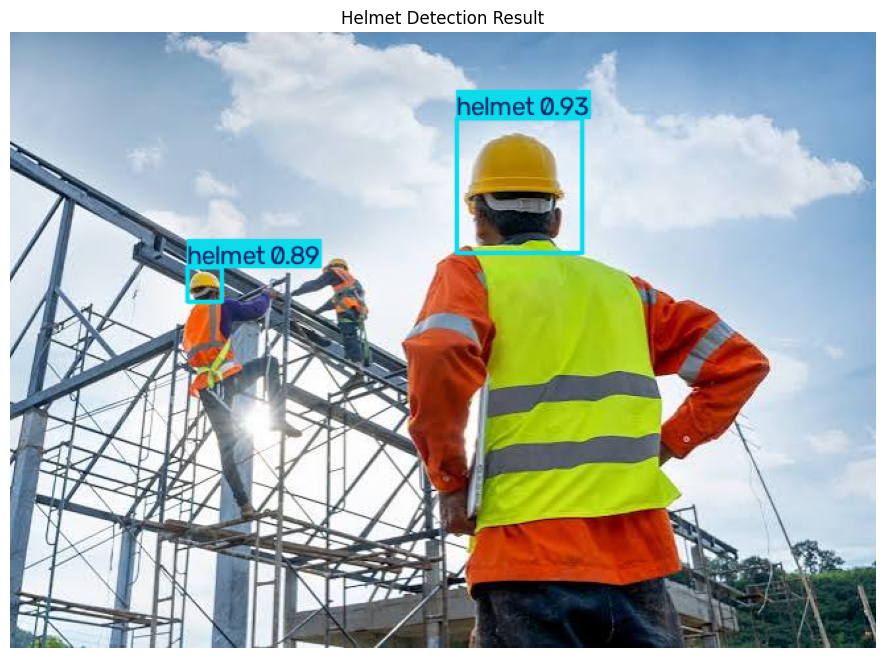

========== Detection Summary ==========
Image: helmet.jpg
Heads detected: 0
Helmets detected: 2
Persons detected: 0
Status: Helmet Detected


In [28]:
from google.colab import files
import os
import cv2
import matplotlib.pyplot as plt

uploaded = files.upload()

for filename in uploaded.keys():

    image_path = filename

    result = model(image_path, verbose=False)[0]

    # Display detections
    annotated = result.plot()

    plt.figure(figsize=(12, 8))
    plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.title("Helmet Detection Result")
    plt.show()

    # Count detections
    head_count = 0
    helmet_count = 0
    person_count = 0

    for cls in result.boxes.cls.cpu().numpy():

        class_name = model.names[int(cls)]

        if class_name == "head":
            head_count += 1
        elif class_name == "helmet":
            helmet_count += 1
        elif class_name == "person":
            person_count += 1

    print("========== Detection Summary ==========")
    print("Image:", filename)
    print("Heads detected:", head_count)
    print("Helmets detected:", helmet_count)
    print("Persons detected:", person_count)

    if head_count > 0:
        print("Status: Possible No Helmet Detection")
    elif helmet_count > 0:
        print("Status: Helmet Detected")
    else:
        print("Status: No Detection")

In [30]:
def detection_summary(image_path, confidence=0.25):

    results = model(image_path, conf=confidence, verbose=False)
    result = results[0]

    helmet_count = 0
    head_count = 0
    person_count = 0

    helmet_conf = []
    head_conf = []

    for box in result.boxes:

        cls = int(box.cls[0])
        conf = float(box.conf[0])

        label = model.names[cls]

        if label == "helmet":
            helmet_count += 1
            helmet_conf.append(conf)

        elif label == "head":
            head_count += 1
            head_conf.append(conf)

        elif label == "person":
            person_count += 1

    print("\n========== Detection Summary ==========")
    print("Image:", os.path.basename(image_path))
    print("Heads detected:", head_count)
    print("Helmets detected:", helmet_count)
    print("Persons detected:", person_count)

    if helmet_conf:
        print("Highest helmet confidence:",
              f"{max(helmet_conf):.2f}")
    else:
        print("Highest helmet confidence: 0.00")

    if head_conf:
        print("Highest head confidence:",
              f"{max(head_conf):.2f}")
    else:
        print("Highest head confidence: 0.00")

    if helmet_count > 0:
        print("Status: Helmet Detected")
    elif head_count > 0:
        print("Status: Potential No Helmet")
    else:
        print("Status: No worker detected")

    print("=======================================")

    return result

In [31]:
result = detection_summary("helmet.jpg")


========== Detection Summary ==========
Image: helmet.jpg
Heads detected: 0
Helmets detected: 2
Persons detected: 0
Highest helmet confidence: 0.93
Highest head confidence: 0.00
Status: Helmet Detected


In [32]:
from google.colab import files

uploaded = files.upload()

Saving 20sec.mp4 to 20sec.mp4


In [33]:
import cv2
from ultralytics import YOLO

video_path = list(uploaded.keys())[0]
output_path = "/content/helmet_output.mp4"

cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

fourcc = cv2.VideoWriter_fourcc(*"mp4v")

out = cv2.VideoWriter(
    output_path,
    fourcc,
    fps,
    (width, height)
)

while True:

    ret, frame = cap.read()

    if not ret:
        break

    results = model(frame, verbose=False)

    annotated_frame = results[0].plot()

    out.write(annotated_frame)

cap.release()
out.release()

print("Video processing completed!")
print("Output:", output_path)

Video processing completed!
Output: /content/helmet_output.mp4


In [34]:
from IPython.display import Video

Video(output_path, embed=True)

In [37]:
import cv2
import os

video_path = "/content/helmet_output.mp4"

cap = cv2.VideoCapture(video_path)

frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

cap.release()

print("Video exists:", os.path.exists(video_path))
print("Frame count:", frame_count)
print("FPS:", fps)
print("Resolution:", width, "x", height)
print("Duration:", round(frame_count / fps, 2), "seconds" if fps > 0 else "unknown")

Video exists: True
Frame count: 607
FPS: 29.97
Resolution: 640 x 360
Duration: 20.25 seconds


In [38]:
print("Runtime is working")

Runtime is working


In [39]:
import pandas as pd

final_csv = "/content/helmet-detection-yolov8/helmet_status_results.csv"

print("Checking file...")

import os
print("File exists:", os.path.exists(final_csv))
print("File size:", os.path.getsize(final_csv), "bytes")

final_df = pd.read_csv(final_csv)

print("CSV loaded successfully!")
display(final_df)

Checking file...
File exists: True
File size: 650 bytes
CSV loaded successfully!


,Image,Head Count,Helmet Count,Person Count,Helmet Confidence,Head Confidence,Overall Status
0,hard_hat_workers42.png,2,5,0,0.93,0.88,No Helmet Detected
1,hard_hat_workers43.png,2,6,0,0.92,0.87,No Helmet Detected
2,hard_hat_workers44.png,0,2,0,0.86,0.00,Helmet Detected
3,hard_hat_workers54.png,6,0,0,0.00,0.90,No Helmet Detected
4,hard_hat_workers55.png,0,6,0,0.90,0.00,Helmet Detected
5,hard_hat_workers56.png,0,2,0,0.92,0.00,Helmet Detected
6,image_1.jpg,0,3,0,0.93,0.00,Helmet Detected
7,image_4.jpg,0,29,0,0.89,0.00,Helmet Detected
8,image_5.jpg,0,16,0,0.94,0.00,Helmet Detected
9,image_6.jpg,1,2,0,0.90,0.93,No Helmet Detected


In [40]:
# Overall project results summary

total_images = len(final_df)
helmet_detected_images = (final_df["Helmet Count"] > 0).sum()
head_detected_images = (final_df["Head Count"] > 0).sum()
no_helmet_images = (final_df["Head Count"] > 0).sum()

total_helmets = final_df["Helmet Count"].sum()
total_heads = final_df["Head Count"].sum()

avg_helmet_conf = final_df.loc[
    final_df["Helmet Confidence"] > 0,
    "Helmet Confidence"
].mean()

avg_head_conf = final_df.loc[
    final_df["Head Confidence"] > 0,
    "Head Confidence"
].mean()

print("=" * 50)
print("       HELMET DETECTION PROJECT SUMMARY")
print("=" * 50)

print(f"Total test images          : {total_images}")
print(f"Images with helmets        : {helmet_detected_images}")
print(f"Images with heads          : {head_detected_images}")
print(f"Total helmets detected     : {total_helmets}")
print(f"Total heads detected       : {total_heads}")

print(f"Average helmet confidence  : {avg_helmet_conf:.2f}")
print(f"Average head confidence    : {avg_head_conf:.2f}")

print("=" * 50)

       HELMET DETECTION PROJECT SUMMARY
Total test images          : 11
Images with helmets        : 10
Images with heads          : 5
Total helmets detected     : 83
Total heads detected       : 12
Average helmet confidence  : 0.91
Average head confidence    : 0.84


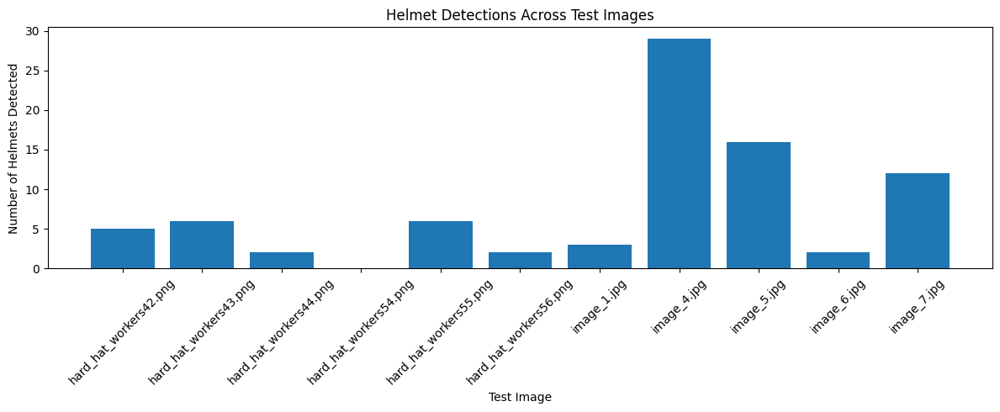

In [41]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.bar(
    final_df["Image"],
    final_df["Helmet Count"]
)

plt.xlabel("Test Image")
plt.ylabel("Number of Helmets Detected")
plt.title("Helmet Detections Across Test Images")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

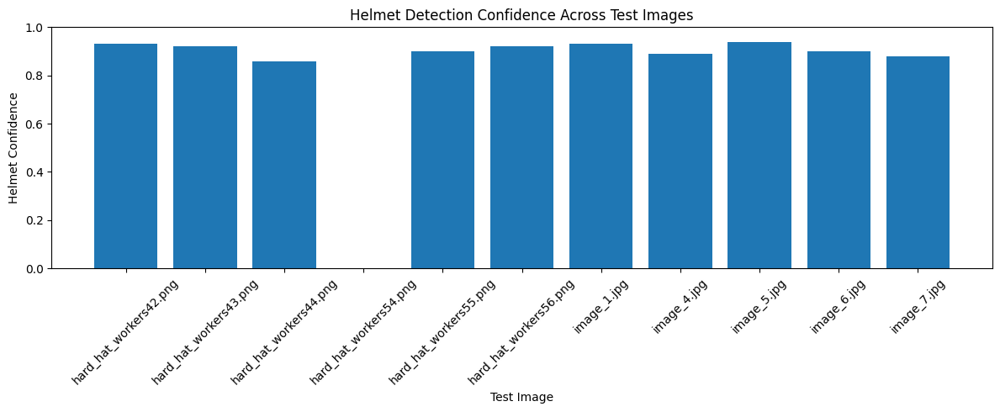

In [42]:
plt.figure(figsize=(12, 5))

plt.bar(
    final_df["Image"],
    final_df["Helmet Confidence"]
)

plt.xlabel("Test Image")
plt.ylabel("Helmet Confidence")
plt.title("Helmet Detection Confidence Across Test Images")

plt.ylim(0, 1)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

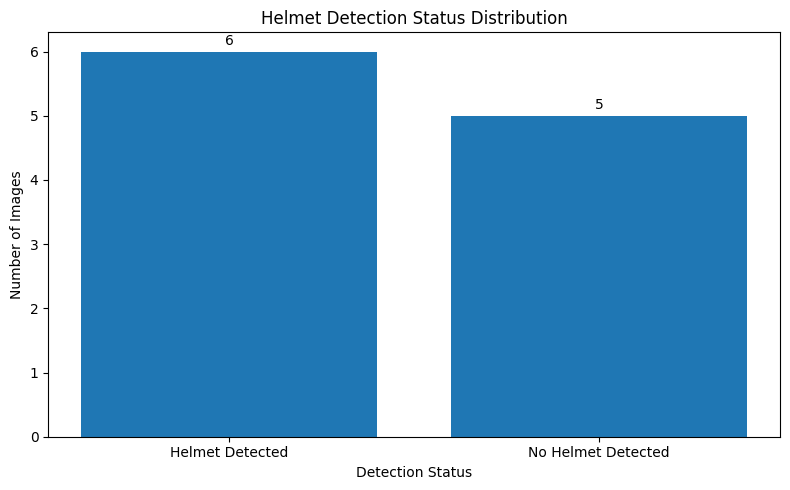

In [43]:
import matplotlib.pyplot as plt
import pandas as pd

# Load final results
final_csv = "/content/helmet-detection-yolov8/helmet_status_results.csv"
df = pd.read_csv(final_csv)

# Count statuses
status_counts = df["Overall Status"].value_counts()

plt.figure(figsize=(8, 5))

plt.bar(status_counts.index, status_counts.values)

plt.xlabel("Detection Status")
plt.ylabel("Number of Images")
plt.title("Helmet Detection Status Distribution")

for i, value in enumerate(status_counts.values):
    plt.text(i, value + 0.1, str(value), ha="center")

plt.tight_layout()
plt.show()

In [44]:
import os

results_folder = "/content/helmet-detection-yolov8/final_results"
os.makedirs(results_folder, exist_ok=True)

print("Results folder created:")
print(results_folder)

Results folder created:
/content/helmet-detection-yolov8/final_results


In [45]:
plt.savefig(
    "/content/helmet-detection-yolov8/final_results/helmet_count_graph.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [46]:
plt.savefig(
    "/content/helmet-detection-yolov8/final_results/confidence_graph.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [48]:
import os

base = "/content/helmet-detection-yolov8/final_results"

os.makedirs(base, exist_ok=True)

print("Final project outputs:")
print(base)

Final project outputs:
/content/helmet-detection-yolov8/final_results


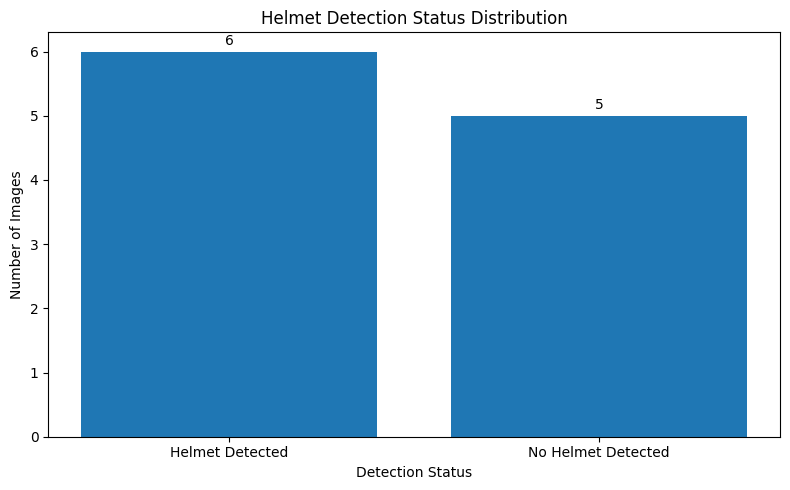

In [49]:
plt.figure(figsize=(8, 5))

status_counts = final_df["Overall Status"].value_counts()

plt.bar(status_counts.index, status_counts.values)

plt.xlabel("Detection Status")
plt.ylabel("Number of Images")
plt.title("Helmet Detection Status Distribution")

for i, value in enumerate(status_counts.values):
    plt.text(i, value + 0.1, str(value), ha="center")

plt.tight_layout()

plt.savefig(
    "/content/helmet-detection-yolov8/final_results/status_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [50]:
import os

folder = "/content/helmet-detection-yolov8/final_results"

print("FINAL RESULTS FILES")
print("=" * 40)

for file in os.listdir(folder):
    print(file)

FINAL RESULTS FILES
status_distribution.png
confidence_graph.png
helmet_count_graph.png
